# 02. 데이터 탐색 (EDA)

01에서 수집한 DART 사업보고서 JSON과 `dart_collection_status.csv`, `company_master.csv`를 결합해 분석에 쓸 corpus의 **분량·연도·섹션·등급·업종** 분포를 점검합니다.

**진행 순서**

1. 입력 데이터 로딩
2. 수집 lineage 점검 (성공/실패 분포, 연도별 성공률)
3. 섹션별 텍스트 길이 분포 (II, IV, VI, VIII, XI)
4. 기업-연도별 총 분량 분포 (롱테일 확인)
5. 연도별 분량 변화 (within-year 패턴)
6. KCGS 등급 분포와 dimension halo effect
7. 업종별 표본 구성과 등급 차이

**원칙**: API를 다시 호출하지 않고 로컬 산출물만 사용합니다. 실패 행은 점수 0으로 채우지 않고 corpus에서 제외합니다.


## 1. 입력 데이터 로딩

JSON 381개를 `(stock_code, fiscal_year, section, text, text_len)` 행으로 펼친 long-format 표와, 기업-연도 단위 wide-format 표를 함께 만듭니다.


In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

warnings.filterwarnings('ignore')

# 한글 폰트 자동 선택
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'NanumGothic', 'Malgun Gothic']:
    if font_name in available_fonts:
        rcParams['font.family'] = font_name
        break
rcParams['axes.unicode_minus'] = False

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = DATA_PROCESSED / 'dart_reports'
STATUS_CSV = DATA_PROCESSED / 'dart_collection_status.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'

EDA_OUTPUT_CSV = DATA_PROCESSED / 'dart_section_lengths.csv'

SECTION_LABELS = ['II', 'IV', 'VI', 'VIII', 'XI']

print('JSON 폴더:', REPORT_DIR, '— 파일 수:', len(list(REPORT_DIR.glob('*.json'))))
print('상태 CSV:', STATUS_CSV, '— exists:', STATUS_CSV.exists())
print('회사 마스터:', COMPANY_MASTER_CSV)


JSON 폴더: /Users/home1/esg-dart-project/data/processed/dart_reports — 파일 수: 381
상태 CSV: /Users/home1/esg-dart-project/data/processed/dart_collection_status.csv — exists: True
회사 마스터: /Users/home1/esg-dart-project/data/raw/company_master.csv


In [2]:
def load_section_lengths() -> pd.DataFrame:
    rows = []
    for path in sorted(REPORT_DIR.glob('*.json')):
        payload = json.loads(path.read_text(encoding='utf-8'))
        sections = payload.get('sections') or {}
        row = {
            'file': path.name,
            'company_name': payload.get('company_name'),
            'stock_code': str(payload.get('stock_code', '')).zfill(6),
            'fiscal_year': payload.get('fiscal_year'),
            'esg_year': payload.get('esg_year'),
            'status': payload.get('status'),
            'rcept_no': payload.get('rcept_no'),
            'acc_mt': payload.get('acc_mt'),
        }
        for label in SECTION_LABELS:
            text = sections.get(label) or ''
            row[f'len_{label}'] = len(text)
        row['len_total'] = sum(row[f'len_{label}'] for label in SECTION_LABELS)
        rows.append(row)
    return pd.DataFrame(rows)


section_lengths = load_section_lengths()
status_df = pd.read_csv(STATUS_CSV) if STATUS_CSV.exists() else pd.DataFrame()
company_master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})
company_master['stock_code'] = company_master['stock_code'].str.replace(r'\.0$', '', regex=True).str.zfill(6)

print('JSON 로드 행 수:', len(section_lengths))
print('상태 CSV 행 수:', len(status_df))
print('company_master 행 수:', len(company_master))
section_lengths.head()


JSON 로드 행 수: 381
상태 CSV 행 수: 381
company_master 행 수: 381


,file,company_name,stock_code,fiscal_year,esg_year,status,rcept_no,acc_mt,len_II,len_IV,len_VI,len_VIII,len_XI,len_total
0,000020_2022.json,동화약품,000020,2022,2023,OK,20230315001100,12,28479,5647,7553,4884,970,47533
1,000020_2023.json,동화약품,000020,2023,2024,OK,20240319000652,12,28945,6207,7507,4743,1254,48656
2,000020_2024.json,동화약품,000020,2024,2025,OK,20250318000739,12,28870,6185,7911,6160,1037,50163
3,000040_2022.json,KR모터스,000040,2022,2023,OK,20230322001182,12,17767,2251,1500,2613,2367,26498
4,000040_2023.json,KR모터스,000040,2023,2024,OK,20240321002062,12,20540,2099,1467,2000,4426,30532


## 2. 수집 lineage 점검

381행 기준 성공/실패 분포와, 연도별 수집 성공률을 확인합니다.


In [3]:
if status_df.empty:
    print('dart_collection_status.csv가 없습니다 — 01 노트북 실행 후 다시 실행하세요.')
else:
    print('전체 행:', len(status_df))
    print('수집 성공:', int(status_df['수집여부'].sum()))
    print('수집 실패:', int((~status_df['수집여부']).sum()))
    by_year = status_df.groupby('esg_year')['수집여부'].agg(['sum', 'count'])
    by_year['success_rate'] = (by_year['sum'] / by_year['count']).round(3)
    print('\n연도별 수집 성공률:')
    print(by_year.to_string())

    if not status_df['수집여부'].all():
        print('\n실패 사유 상위 10개:')
        print(status_df.loc[~status_df['수집여부'], '실패사유'].value_counts().head(10).to_string())


전체 행: 381
수집 성공: 381
수집 실패: 0

연도별 수집 성공률:
          sum  count  success_rate
esg_year                          
2023      127    127           1.0
2024      127    127           1.0
2025      127    127           1.0


## 3. 섹션별 텍스트 길이 분포

5개 섹션(II, IV, VI, VIII, XI)이 각각 얼마나 두꺼운지 평균/중앙값/분포로 확인합니다.

- II(사업의 내용)과 VI(이사회)는 일반적으로 가장 길고
- IV(경영진단), VIII(임원·직원), XI(투자자 보호)는 상대적으로 짧을 가능성


In [4]:
ok_mask = section_lengths['status'] == 'OK'
ok = section_lengths.loc[ok_mask].copy()

len_cols = [f'len_{label}' for label in SECTION_LABELS]
section_summary = ok[len_cols].describe().T.round(0)
section_summary.index = SECTION_LABELS
print('성공 행 기준 섹션별 글자 수 분포 (n={})'.format(len(ok)))
print(section_summary[['mean', '50%', 'min', 'max']].to_string())


성공 행 기준 섹션별 글자 수 분포 (n=381)
         mean      50%     min       max
II    44283.0  30102.0  2070.0  292538.0
IV    18602.0  12019.0  2046.0  202909.0
VI    15531.0  13900.0  1357.0   47034.0
VIII  11866.0   7611.0  2000.0  128812.0
XI    12194.0   5230.0   150.0  125046.0


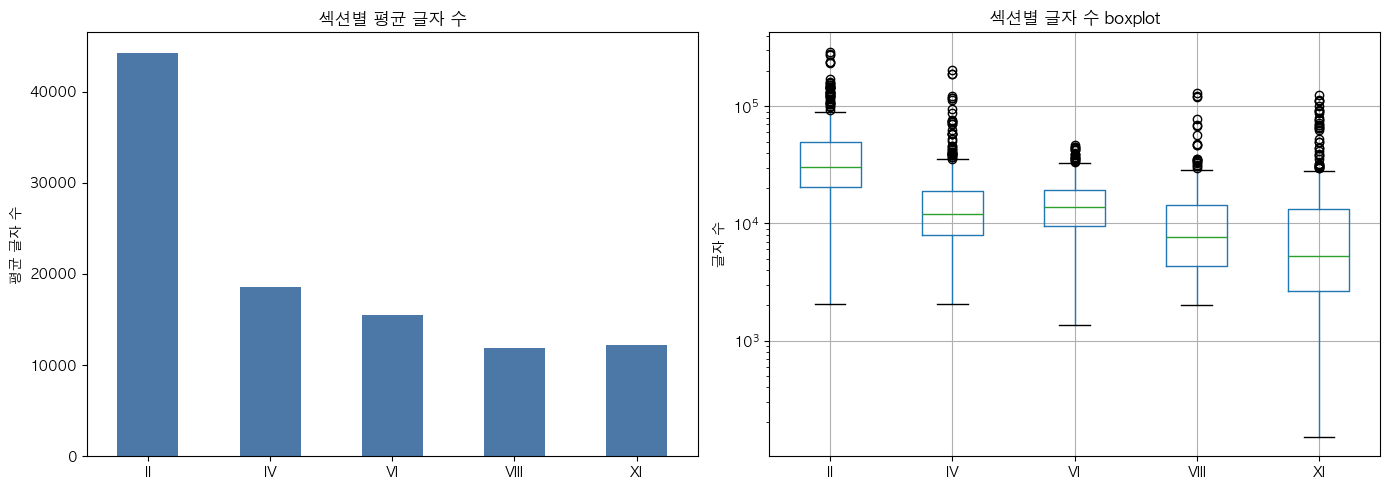

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ok[len_cols].mean().plot(
    kind='bar', ax=axes[0], color='#4C78A8',
    title='섹션별 평균 글자 수',
)
axes[0].set_xticklabels(SECTION_LABELS, rotation=0)
axes[0].set_ylabel('평균 글자 수')

ok[len_cols].boxplot(ax=axes[1])
axes[1].set_title('섹션별 글자 수 boxplot')
axes[1].set_xticklabels(SECTION_LABELS, rotation=0)
axes[1].set_ylabel('글자 수')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()


## 4. 기업-연도별 총 분량 분포

5개 섹션 합계 글자 수를 기업-연도 단위로 보면 일부 대기업이 분포를 끌고 가는 **롱테일** 구조가 보일 것입니다. 이 점은 후속 단계에서 cheap-talk(공시 장황함) 통제 변수의 필요성을 시사합니다.


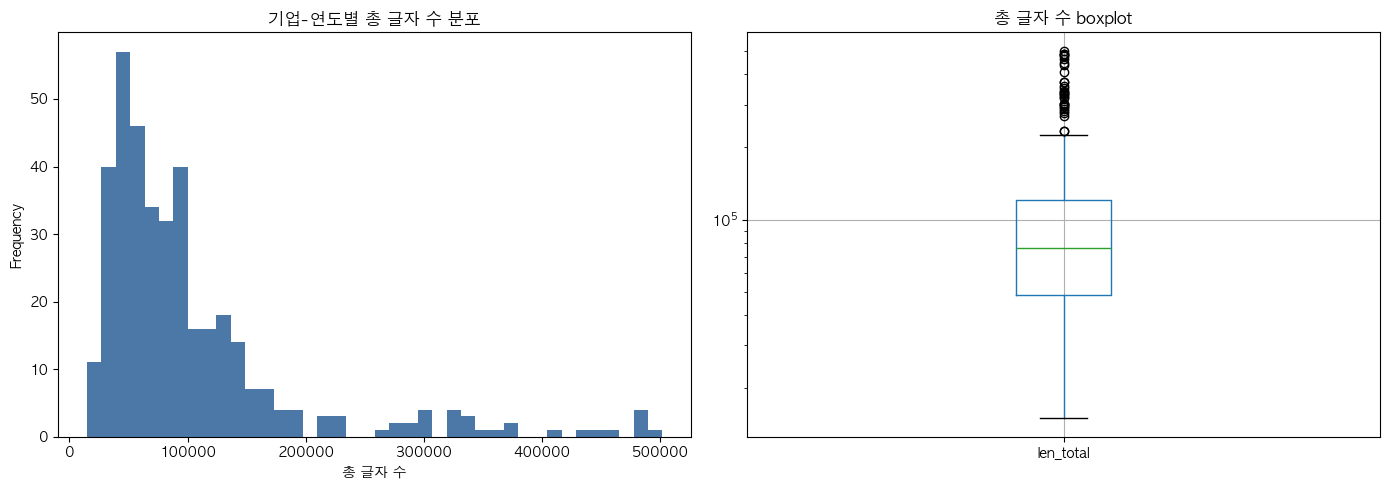

상위 10개 기업-연도 (총 글자 수 기준):
company_name  fiscal_year  esg_year  len_total
        KB금융         2024      2025     501626
          한화         2024      2025     486337
    POSCO홀딩스         2023      2024     485177
      KB금융지주         2022      2023     482831
        KB금융         2023      2024     477405
    POSCO홀딩스         2024      2025     463694
          한화         2023      2024     445413
    POSCO홀딩스         2022      2023     438986
          한화         2022      2023     410350
        신한지주         2024      2025     373825


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ok['len_total'].plot(
    kind='hist', bins=40, ax=axes[0], color='#4C78A8',
    title='기업-연도별 총 글자 수 분포',
)
axes[0].set_xlabel('총 글자 수')

ok[['len_total']].boxplot(ax=axes[1])
axes[1].set_title('총 글자 수 boxplot')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

print('상위 10개 기업-연도 (총 글자 수 기준):')
print(
    ok.nlargest(10, 'len_total')[['company_name', 'fiscal_year', 'esg_year', 'len_total']]
    .to_string(index=False)
)


## 5. 연도별 분량 변화

ESG 공시는 매년 증가하는 추세입니다. 연도별 평균/중앙값 글자 수를 확인하면 within-year 비교가 의미가 있는지 판단할 수 있습니다.


연도별 분량 요약:
            n  mean_total  median_total  mean_II  mean_IV  mean_VI  mean_VIII  mean_XI
esg_year                                                                              
2023      127     99022.0       74938.0  43530.0  17984.0  14969.0    11442.0  11096.0
2024      127    103235.0       76038.0  44896.0  18977.0  15438.0    11546.0  12378.0
2025      127    105169.0       76242.0  44423.0  18846.0  16185.0    12609.0  13106.0


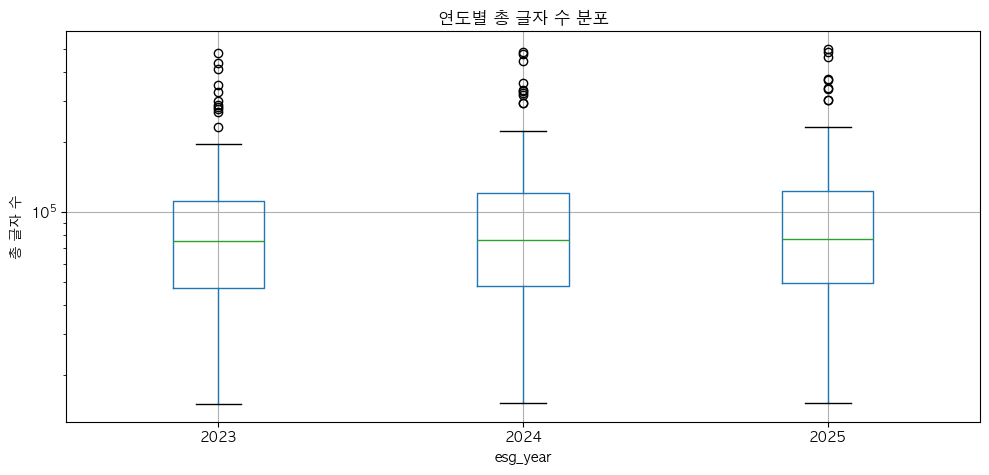

In [7]:
by_year = ok.groupby('esg_year').agg(
    n=('len_total', 'size'),
    mean_total=('len_total', 'mean'),
    median_total=('len_total', 'median'),
    **{f'mean_{label}': (f'len_{label}', 'mean') for label in SECTION_LABELS},
).round(0)
print('연도별 분량 요약:')
print(by_year.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
ok.boxplot(column='len_total', by='esg_year', ax=ax)
ax.set_title('연도별 총 글자 수 분포')
ax.set_xlabel('esg_year')
ax.set_ylabel('총 글자 수')
ax.set_yscale('log')
plt.suptitle('')
plt.tight_layout()
plt.show()


## 6. KCGS 등급 분포와 dimension halo effect

ESG 등급은 D~S의 서열변수입니다. 분포가 어느 등급에 몰려 있는지 확인하고, E/S/G 세부 등급 간 상관(halo effect)을 봅니다. halo가 강하면 dimension별 분리 모형의 부가가치가 약해집니다.


corpus에 포함된 기업-연도: 381 / 381


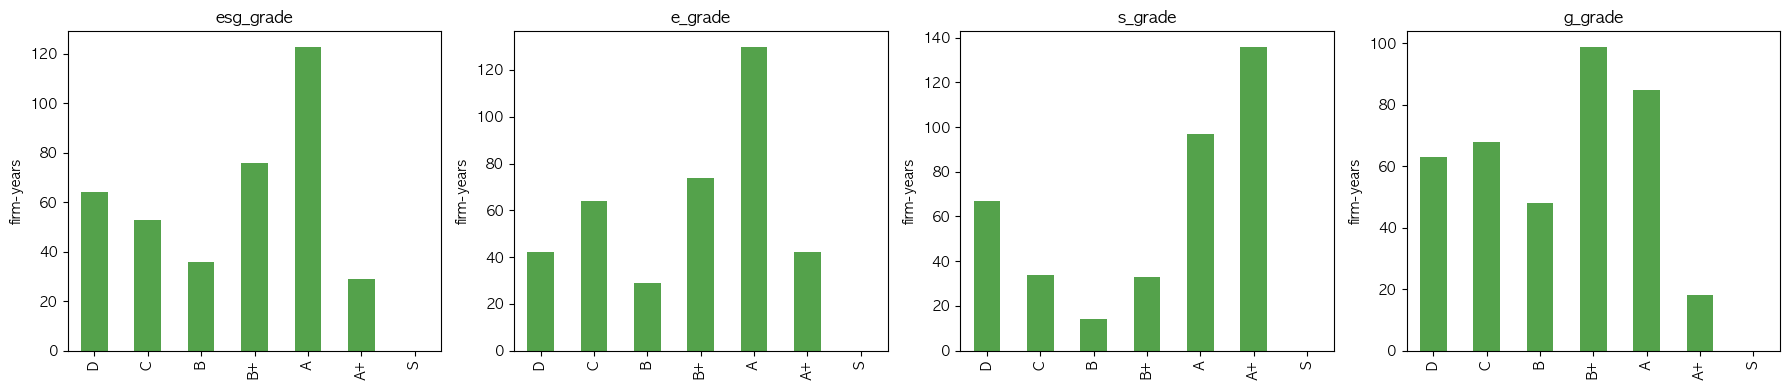


각 등급 평균(숫자 환산, 0=D ~ 6=S):
esg_grade_num    2.60
e_grade_num      2.82
s_grade_num      3.23
g_grade_num      2.34


In [8]:
GRADE_MAP = {'D': 0, 'C': 1, 'B': 2, 'B+': 3, 'A': 4, 'A+': 5, 'S': 6}
GRADE_ORDER = list(GRADE_MAP.keys())

panel = company_master.copy()
for col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    panel[f'{col}_num'] = panel[col].map(GRADE_MAP)

# 수집 성공한 기업-연도만 분석에 포함
ok_keys = ok[['stock_code', 'fiscal_year']].copy()
panel = panel.merge(ok_keys.assign(_in_corpus=True), on=['stock_code', 'fiscal_year'], how='left')
panel_corpus = panel.loc[panel['_in_corpus'].fillna(False)].copy()

print(f'corpus에 포함된 기업-연도: {len(panel_corpus)} / {len(panel)}')

grade_cols = ['esg_grade', 'e_grade', 's_grade', 'g_grade']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, grade_cols):
    panel_corpus[col].value_counts().reindex(GRADE_ORDER).fillna(0).plot(
        kind='bar', ax=ax, color='#54A24B', title=col,
    )
    ax.set_xlabel('')
    ax.set_ylabel('firm-years')
plt.tight_layout()
plt.show()

print('\n각 등급 평균(숫자 환산, 0=D ~ 6=S):')
print(panel_corpus[[f'{c}_num' for c in grade_cols]].mean().round(2).to_string())


In [9]:
# E/S/G halo effect (Spearman)
halo_cols = ['e_grade_num', 's_grade_num', 'g_grade_num']
if SCIPY_AVAILABLE:
    halo_data = panel_corpus[halo_cols].dropna()
    halo = pd.DataFrame(index=halo_cols, columns=halo_cols, dtype=float)
    for a in halo_cols:
        for b in halo_cols:
            halo.loc[a, b] = stats.spearmanr(halo_data[a], halo_data[b]).statistic
    print('E/S/G 등급 간 Spearman 순위상관 (halo effect)')
    print(halo.round(3).to_string())
else:
    print('scipy가 없어 halo 분석 생략')


E/S/G 등급 간 Spearman 순위상관 (halo effect)
             e_grade_num  s_grade_num  g_grade_num
e_grade_num        1.000        0.792        0.683
s_grade_num        0.792        1.000        0.681
g_grade_num        0.683        0.681        1.000


## 7. 업종별 표본 구성과 등급 차이

표본이 어떤 업종에 치우쳐 있는지, 업종 간 ESG 등급에 의미 있는 차이가 있는지 확인합니다. 회귀 단계에서 industry fixed effect 필요성을 가늠하는 근거입니다.


업종별 firm-year 수 (상위 15개):
industry
금융지주       15
인터넷/플랫폼     6
화학          6
전기전자        3
섬유/의류       3
자동차         3
물류          3
식품          3
지주회사        3
미디어/콘텐츠     3
유통          3
식자재유통       3
반도체         3
게임          3
IT서비스       3

업종별 등급 평균 (상위 10개):
           n  mean_esg  mean_e  mean_s  mean_g
industry                                      
금융지주      15      4.33    4.87    4.47    4.27
화학         6      3.33    3.33    4.83    2.83
인터넷/플랫폼    6      4.17    4.33    4.83    3.83
에너지/화학     3      4.67    3.67    5.00    5.00
철강         3      4.67    4.00    5.00    4.67
지주회사       3      3.67    4.00    5.00    3.00
정유         3      4.33    3.33    4.67    4.33
전기전자       3      3.67    3.33    4.67    2.67
자동차        3      4.00    4.67    3.33    3.33
은행         3      3.00    5.00    5.00    2.33

상위 8개 업종 간 Kruskal-Wallis: H=23.82, p=0.0012


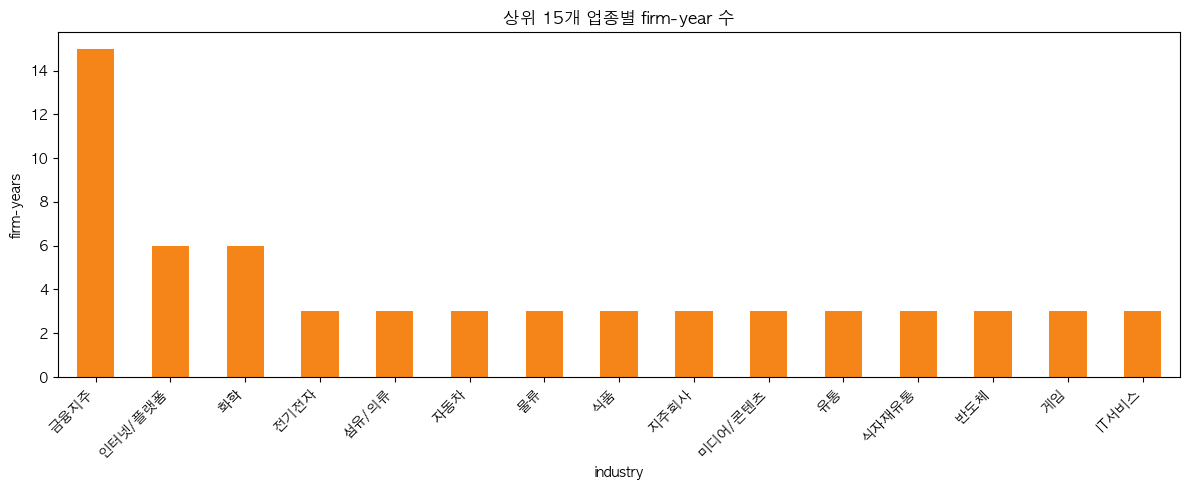

In [10]:
industry_counts = panel_corpus['industry'].value_counts()
print('업종별 firm-year 수 (상위 15개):')
print(industry_counts.head(15).to_string())

industry_grade = panel_corpus.groupby('industry').agg(
    n=('esg_grade_num', 'size'),
    mean_esg=('esg_grade_num', 'mean'),
    mean_e=('e_grade_num', 'mean'),
    mean_s=('s_grade_num', 'mean'),
    mean_g=('g_grade_num', 'mean'),
).round(2).sort_values('n', ascending=False)
print('\n업종별 등급 평균 (상위 10개):')
print(industry_grade.head(10).to_string())

if SCIPY_AVAILABLE:
    top_industries = industry_counts.head(8).index.tolist()
    groups = [
        panel_corpus.loc[panel_corpus['industry'] == ind, 'esg_grade_num'].dropna().values
        for ind in top_industries
    ]
    groups = [g for g in groups if len(g) >= 3]
    if len(groups) >= 2:
        kw = stats.kruskal(*groups)
        print(f'\n상위 {len(groups)}개 업종 간 Kruskal-Wallis: H={kw.statistic:.2f}, p={kw.pvalue:.4f}')

fig, ax = plt.subplots(figsize=(12, 5))
industry_counts.head(15).plot(kind='bar', ax=ax, color='#F58518')
ax.set_title('상위 15개 업종별 firm-year 수')
ax.set_ylabel('firm-years')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 8. EDA 산출물 저장

후속 단계(전처리, 피처 엔지니어링)에서 참조하기 쉽도록 섹션별 길이 표 하나만 저장합니다. (요구사양: 탐색 단계의 CSV는 최소화)


In [11]:
out_cols = ['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'status'] + len_cols + ['len_total']
section_lengths[out_cols].to_csv(EDA_OUTPUT_CSV, index=False, encoding='utf-8-sig')
print('저장:', EDA_OUTPUT_CSV)
print('shape:', section_lengths[out_cols].shape)


저장: /Users/home1/esg-dart-project/data/processed/dart_section_lengths.csv
shape: (381, 11)


## 요약

- 섹션별 분량은 VI(이사회)와 II(사업의 내용)이 가장 길고, IV·VIII·XI는 짧은 편
- 기업-연도 총 분량은 롱테일 → cheap-talk 통제 변수 필요
- KCGS 등급은 A 부근에 몰리는 class imbalance, dimension 간 halo effect 존재
- 업종 편중이 강해 회귀 단계에서 industry 통제를 고려해야 함
